In [27]:
import os
os.environ["TORCH_COMPILE_DISABLE"] = "1"

import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from tqdm import tqdm

device = torch.device("cpu")
torch.manual_seed(0)
np.random.seed(0)

# ========================================================================================
# 1. DATA SETUP & MOCK DATA SETUP
# ========================================================================================
# Using synthetic generation if dataset file isn't found locally
try:
    df = pd.read_csv("ai_student_impact_dataset (1).csv", encoding="windows-1252").dropna()
except FileNotFoundError:
    print("[!] Local dataset file not found. Generating a synchronized mock array for structural verification...")
    mock_len = 600
    df = pd.DataFrame({
        'Student_ID': range(1000, 1000 + mock_len),
        'Weekly_GenAI_Hours': np.random.uniform(0, 24, mock_len),
        'Traditional_Study_Hours': np.random.uniform(5, 35, mock_len),
        'Pre_Semester_GPA': np.random.uniform(1.5, 4.0, mock_len),
        'Age': np.random.randint(18, 25, mock_len),
        'Major_STEM': np.random.choice([0, 1], mock_len),
        'Post_Semester_GPA': np.random.uniform(1.5, 4.0, mock_len)
    })

X_raw = df.drop(columns=['Student_ID', 'Post_Semester_GPA'])
X = pd.get_dummies(X_raw, dtype=int).astype(float)

sensitive_names = ['Weekly_GenAI_Hours', 'Traditional_Study_Hours', 'Pre_Semester_GPA']
X_published = X.drop(columns=sensitive_names)
published_names = list(X_published.columns)

victim_scaler = StandardScaler()
X_victim_scaled = victim_scaler.fit_transform(X.values)
X_train_tensor = torch.tensor(X_victim_scaled, dtype=torch.float32, device=device)

surrogate_scaler = StandardScaler()
X_pub_scaled_values = surrogate_scaler.fit_transform(X_published.values)
X_pub_train_tensor = torch.tensor(X_pub_scaled_values, dtype=torch.float32, device=device)

sensitive_indices = [X.columns.get_loc(name) for name in sensitive_names]
X_sensitive_tensor = torch.tensor(X_victim_scaled[:, sensitive_indices], dtype=torch.float32, device=device)

# ========================================================================================
# 1B. TRUE TARGET VICTIM MODEL TRAINING
# ========================================================================================
print("[*] Stage -1: Training a Genuine Non-Linear Target Victim Model...")

class DeepVictimModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128), nn.SiLU(),
            nn.Linear(128, 64), nn.SiLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x): return self.net(x)

victim_model = DeepVictimModel(input_dim=X.shape[1]).to(device)
victim_optimizer = optim.AdamW(victim_model.parameters(), lr=0.005, weight_decay=1e-4)
victim_criterion = nn.MSELoss()

Yc = df['Post_Semester_GPA'].values
y_true_scaled = (torch.tensor(Yc, dtype=torch.float32, device=device) - Yc.mean()) / (Yc.std() + 1e-6)

victim_model.train()
for epoch in range(300):
    victim_optimizer.zero_grad()
    predictions = victim_model(X_train_tensor).squeeze(-1)
    loss = victim_criterion(predictions, y_true_scaled)
    loss.backward()
    victim_optimizer.step()

victim_model.eval()
print(f"[+] Victim model trained. Final Training MSE: {loss.item():.4f}")

# ========================================================================================
# 2. DEFINING REALISTIC ADVERSARIAL TARGET BOUNDARIES (0% NOISE DISTORTION, SEED=0)
# ========================================================================================
true_bounds_min = torch.tensor([0.0, 0.0, 1.5], device=device)
true_bounds_max = torch.tensor([24.0, 35.0, 4.0], device=device)
bound_ranges = true_bounds_max - true_bounds_min
noise_scale = 0.0

min_bound_noise = (torch.rand(len(sensitive_names), device=device) - 0.5) * 2.0 * noise_scale * bound_ranges
max_bound_noise = (torch.rand(len(sensitive_names), device=device) - 0.5) * 2.0 * noise_scale * bound_ranges

known_bounds_min = torch.clamp(true_bounds_min + min_bound_noise, min=0.0)
known_bounds_max = true_bounds_max + max_bound_noise
profile_delta = known_bounds_max - known_bounds_min

# ========================================================================================
# 3. STAGE 0: JACOBIAN MANIFOLD ALIGNMENT (1000 ROW POOL)
# ========================================================================================
# Dynamically expanding training rows to cover a massive 1000-row baseline pool.
# This gives the surrogate model an expansive field of view over non-linear slopes.
train_cutoff = min(1000, len(X_pub_train_tensor) - 100)

X_pub_aux_train = X_pub_train_tensor[:train_cutoff]
num_aux_samples = len(X_pub_aux_train)
dim_t = len(sensitive_names)

print(f"[*] Stage 0: Training Aligned Surrogate via Expanded Pool ({num_aux_samples} Rows)...")

# Generate synthetic positions across the boundary profiles
sobol_engine = torch.quasirandom.SobolEngine(dimension=dim_t, scramble=True, seed=0)
X_t_qmc_sandbox = sobol_engine.draw(num_aux_samples).to(device)
physical_qmc_targets = known_bounds_min + X_t_qmc_sandbox * profile_delta

f_surrogate_scaler = StandardScaler()
scaled_qmc_targets_numpy = f_surrogate_scaler.fit_transform(physical_qmc_targets.cpu().numpy())
scaled_qmc_targets_tensor = torch.tensor(scaled_qmc_targets_numpy, dtype=torch.float32, device=device)

class JacobianClone(nn.Module):
    def __init__(self, dim_pub, dim_t):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim_pub + dim_t, 256), nn.SiLU(),
            nn.Linear(256, 128), nn.SiLU(),
            nn.Linear(128, 64), nn.SiLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x_pub, x_t):
        return self.net(torch.cat([x_pub, x_t], dim=-1)).squeeze(-1)

f_surrogate = JacobianClone(dim_pub=len(published_names), dim_t=dim_t).to(device)
clone_opt = optim.AdamW(f_surrogate.parameters(), lr=0.001, weight_decay=1e-4)

# Create an aligned query block for auxiliary data
X_query_base = torch.zeros((num_aux_samples, X.shape[1]), device=device)
for i, name in enumerate(published_names):
    X_query_base[:, X.columns.get_loc(name)] = X_pub_aux_train[:, i]
for i, name in enumerate(sensitive_names):
    X_query_base[:, X.columns.get_loc(name)] = scaled_qmc_targets_tensor[:, i]

# First-order gradient matching loop
f_surrogate.train()
pbar_surr = tqdm(range(2000), desc="Tuning Expanded Jacobian Surrogate")
for epoch in pbar_surr:
    clone_opt.zero_grad()

    # Inject a micro-epsilon perturbation into the sensitive channels
    eps = torch.randn_like(scaled_qmc_targets_tensor) * 0.01
    perturbed_sensitive = scaled_qmc_targets_tensor + eps

    X_query_perturbed = X_query_base.clone()
    for i, name in enumerate(sensitive_names):
        X_query_perturbed[:, X.columns.get_loc(name)] = perturbed_sensitive[:, i]

    # Query the black-box oracle
    with torch.no_grad():
        y_base = victim_model(X_query_base).squeeze(-1)
        y_perturbed = victim_model(X_query_perturbed).squeeze(-1)
        true_slope = (y_perturbed - y_base)

    # Compute surrogate predictions and match the empirical derivatives
    pred_base = f_surrogate(X_pub_aux_train, scaled_qmc_targets_tensor)
    pred_perturbed = f_surrogate(X_pub_aux_train, perturbed_sensitive)
    surr_slope = (pred_perturbed - pred_base)

    loss_val = nn.functional.huber_loss(pred_base, y_base, delta=0.1)
    loss_slope = nn.functional.mse_loss(surr_slope, true_slope)

    total_loss = loss_val + 10.0 * loss_slope
    total_loss.backward()
    clone_opt.step()

    if epoch % 100 == 0:
        pbar_surr.set_postfix({"Surr_Loss": f"{total_loss.item():.5f}"})

t_mean = torch.tensor(f_surrogate_scaler.mean_, dtype=torch.float32, device=device)
t_std = torch.tensor(np.sqrt(f_surrogate_scaler.var_), dtype=torch.float32, device=device) + 1e-6
print(f"[+] Expanded Surrogate ready for parallel validation. Final Loss: {total_loss.item():.5f}")

# ========================================================================================
# 4. OVERHAULED: DISJOINT MULTI-HEAD CRITIC ARCHITECTURE (ELIMINATES TASK DOMINANCE)
# ========================================================================================
class ResidualBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.block = nn.Sequential(
            nn.Linear(dim, dim), nn.LayerNorm(dim), nn.SiLU(),
            nn.Linear(dim, dim), nn.LayerNorm(dim)
        )
        self.act = nn.SiLU()
    def forward(self, x): return self.act(x + self.block(x))

class DecoupledMultiHeadGenerator(nn.Module):
    def __init__(self, dim_pub, dim_z, dim_t):
        super().__init__()
        self.dim_t = int(dim_t)
        int_pub = int(dim_pub) if isinstance(dim_pub, (torch.Size, tuple, list)) else int(dim_pub)

        self.joint_projection = nn.Sequential(
            nn.Linear(int_pub + 1, 128), nn.SiLU(), nn.Linear(128, 128), nn.LayerNorm(128)
        )
        self.shared_core = nn.Sequential(
            nn.Linear(128 + int(dim_z), 256), nn.LayerNorm(256), nn.SiLU(),
            ResidualBlock(256)
        )
        # Independent neural heads map coordinates within the normalized activation hypercube
        self.output_heads = nn.ModuleList([
            nn.Sequential(nn.Linear(256, 128), nn.SiLU(), nn.Linear(128, 1))
            for _ in range(self.dim_t)
        ])
    def forward(self, x_pub, y, z):
        embedded_context = self.joint_projection(torch.cat([x_pub, y.unsqueeze(-1)], dim=-1))
        shared_features = self.shared_core(torch.cat([embedded_context, z], dim=-1))
        head_outputs = [torch.clamp(torch.tanh(head(shared_features).squeeze(-1)) * 0.5 + 0.5, min=0.0, max=1.0) for head in self.output_heads]
        return torch.stack(head_outputs, dim=-1)

class JointManifoldCritic(nn.Module):
    def __init__(self, dim_pub, dim_t):
        super().__init__()
        self.dim_t = int(dim_t)
        int_pub = int(dim_pub) if isinstance(dim_pub, (torch.Size, tuple, list)) else int(dim_pub)

        # BREAKTHROUGH: Disjoint independent feature extractors prevent task dominance masking.
        # LayerNorm is COMPLETELY removed to preserve strict 1-Lipschitz continuity bounds.
        self.feature_heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(int_pub + 1, 128), nn.SiLU(),
                nn.Linear(128, 64), nn.SiLU()
            ) for _ in range(self.dim_t)
        ])
        self.critic_heads = nn.ModuleList([nn.Linear(64, 1) for _ in range(self.dim_t)])

    def forward(self, x_pub, x_t):
        scores = []
        feats = []
        # Force the critic to score each sensitive attribute independently
        for i in range(self.dim_t):
            single_attr = x_t[:, i].unsqueeze(-1)
            feat = self.feature_heads[i](torch.cat([x_pub, single_attr], dim=-1))
            feats.append(feat)
            scores.append(self.critic_heads[i](feat).squeeze(-1))

        total_score = torch.stack(scores, dim=-1).mean(dim=-1)
        total_feats = torch.cat(feats, dim=-1)
        return total_score, total_feats

# ========================================================================================
# 5. STAGE 1: FULLY SYNCHRONIZED JOINT ADVERSARIAL TRAVERSAL LOOPS
# ========================================================================================
def execute_wasserstein_inversion_distillation(X_pub_aux, batch_size=256, epochs=3000):
    print("\n[*] Launching Stage 1: Running Leak-Free Joint WGAN-GP Loop via Automated Weight Pacing...")
    local_dim_t = len(sensitive_names)
    num_synthetic_samples = len(X_pub_aux)

    sobol_train = torch.quasirandom.SobolEngine(dimension=local_dim_t, scramble=True, seed=0)
    X_t_train_pool = sobol_train.draw(num_synthetic_samples).to(device)
    X_pub_train_pool = X_pub_aux.clone().detach()

    num_pub_features = X_pub_train_pool.shape[1]
    num_target_features = X_t_train_pool.shape[1]
    dim_z = 32

    netG = DecoupledMultiHeadGenerator(num_pub_features, dim_z, num_target_features).to(device)
    netC = JointManifoldCritic(num_pub_features, num_target_features).to(device)

    # --- 1. CRITICAL INITIALIZATION: HOMOSCEDASTIC LEARNABLE TASK PRECISION REGISTERS ---
    # These parameters act as trainable uncertainty filters. The network will automatically
    # balance the weights on the fly based on current gradient scale changes.
    log_var_surr = nn.Parameter(torch.ones(1, device=device) * 2.0) # Starts weight at ~exp(-2)
    log_var_feat = nn.Parameter(torch.ones(1, device=device) * 1.0) # Starts weight at ~exp(-1)

    # Register the uncertainty weights into the Generator's optimizer tape
    optG = optim.AdamW([
        {'params': netG.parameters()},
        {'params': [log_var_surr, log_var_feat]}
    ], lr=0.0005, betas=(0.5, 0.9), weight_decay=1e-4)

    optC = optim.AdamW(netC.parameters(), lr=0.00001, betas=(0.5, 0.9))

    f_surrogate.eval()
    pbar = tqdm(range(epochs), desc="Auto-Balanced WGAN Loop")
    critic_updates_per_gen = 5

    for epoch in pbar:
        noise_scale = max(0.1, 1.0 - (epoch / epochs))

        # --------------------------------------------------------------------------------
        # 1. CRITIC TRAINING STEP: 1-LIPSCHITZ BOUND PROTECTION
        # --------------------------------------------------------------------------------
        for _ in range(critic_updates_per_gen):
            indices = np.random.choice(len(X_pub_train_pool), batch_size, replace=True)
            real_pub, real_target_t = X_pub_train_pool[indices], X_t_train_pool[indices]

            with torch.no_grad():
                physical_t_synthetic = known_bounds_min + real_target_t * profile_delta
                scaled_for_surr = (physical_t_synthetic - t_mean) / (t_std + 1e-6)
                real_y = f_surrogate(real_pub, scaled_for_surr)

            optC.zero_grad()
            real_scores, _ = netC(real_pub, real_target_t)
            z = torch.randn(batch_size, dim_z, device=device) * noise_scale
            fake_target_t = netG(real_pub, real_y, z)
            fake_scores, _ = netC(real_pub, fake_target_t.detach())

            alpha = torch.rand(batch_size, 1, device=device)
            interpolates = (alpha * real_target_t + ((1 - alpha) * fake_target_t.detach())).requires_grad_(True)
            d_outputs, _ = netC(real_pub, interpolates)

            fake_grad_outputs = torch.ones(d_outputs.shape, device=device)
            grad_outputs = torch.autograd.grad(
                outputs=d_outputs, inputs=interpolates, grad_outputs=fake_grad_outputs,
                create_graph=True, retain_graph=True, only_inputs=True
            )
            gradients = grad_outputs[0].view(grad_outputs[0].size(0), -1)
            gp = ((gradients.norm(2, dim=1) - 1.0) ** 2).mean()

            loss_C = fake_scores.mean() - real_scores.mean() + 10.0 * gp
            loss_C.backward()
            optC.step()

        # --------------------------------------------------------------------------------
        # 2. GENERATOR TRAINING STEP: SELF-BALANCING MULTI-OBJECTIVE SEGMENT
        # --------------------------------------------------------------------------------
        optG.zero_grad()

        z_fresh = torch.randn(batch_size, dim_z, device=device) * noise_scale
        fake_target_t_g = netG(real_pub, real_y, z_fresh)

        fake_scores_g, fake_feats_g = netC(real_pub, fake_target_t_g)
        _, real_feats = netC(real_pub, real_target_t)

        loss_adversarial = -fake_scores_g.mean()

        # Calculate proxy objective alignments
        physical_fake_t = known_bounds_min + fake_target_t_g * profile_delta
        scaled_fake_for_surr = (physical_fake_t - t_mean) / (t_std + 1e-6)
        pred_y_from_fake = f_surrogate(real_pub, scaled_fake_for_surr)

        loss_surr = nn.functional.mse_loss(pred_y_from_fake, real_y)
        loss_feature_matching = nn.functional.mse_loss(fake_feats_g, real_feats.detach())

        # --- 2. MULTI-TASK HOMOSCEDASTIC GRADIENT ADAPTATION FORMULA (ZERO LEAKAGE) ---
        # Derive precision tracking scales on the fly to protect the optimization tape
        precision_surr = torch.exp(-log_var_surr)
        precision_feat = torch.exp(-log_var_feat)

        # Balance losses using learnable variances coupled with logarithmic norm protectors
        weighted_surr = precision_surr * loss_surr + log_var_surr
        weighted_feat = precision_feat * loss_feature_matching + log_var_feat

        # Execute total combined loss vector
        loss_G = loss_adversarial + weighted_surr + weighted_feat
        loss_G.backward()
        optG.step()

        # Extract dynamic absolute weights for terminal logging display
        with torch.no_grad():
            current_w_surr = torch.exp(-log_var_surr).item()
            current_w_feat = torch.exp(-log_var_feat).item()

        pbar.set_postfix({
            "Loss_C": f"{loss_C.item():.4f}",
            "Loss_G": f"{loss_G.item():.4f}",
            "w_surr": f"{current_w_surr:.3f}",
            "w_feat": f"{current_w_feat:.3f}"
        })

    return netG

X_pub_only_scaled = X_pub_train_tensor.clone().detach()
netG = execute_wasserstein_inversion_distillation(X_pub_only_scaled[:train_cutoff], batch_size=256, epochs=4000)

[*] Stage -1: Training a Genuine Non-Linear Target Victim Model...
[+] Victim model trained. Final Training MSE: 0.0848
[*] Stage 0: Training Aligned Surrogate via Expanded Pool (1000 Rows)...


Tuning Expanded Jacobian Surrogate: 100%|██████████| 2000/2000 [00:14<00:00, 141.13it/s, Surr_Loss=0.00001]


[+] Expanded Surrogate ready for parallel validation. Final Loss: 0.00000

[*] Launching Stage 1: Running Leak-Free Joint WGAN-GP Loop via Automated Weight Pacing...


Auto-Balanced WGAN Loop: 100%|██████████| 4000/4000 [06:07<00:00, 10.89it/s, Loss_C=0.0589, Loss_G=-0.7341, w_surr=1.000, w_feat=2.718]



=== PRE-INFERENCE DOCUMENTATION: REALIGNED GAUSSIAN PROFILE VS ACTUAL (Xt) ===
Sensitive Attribute       | Prior Bounds Profile   | EMD (WGAN vs Actual Xt)
-------------------------------------------------------------------------------------
Weekly_GenAI_Hours        | [  0.00,  24.00] | 4.675184
Traditional_Study_Hours   | [  0.00,  35.00] | 10.619468
Pre_Semester_GPA          | [  1.50,   4.00] | 0.528836
[+] Plot generated successfully.


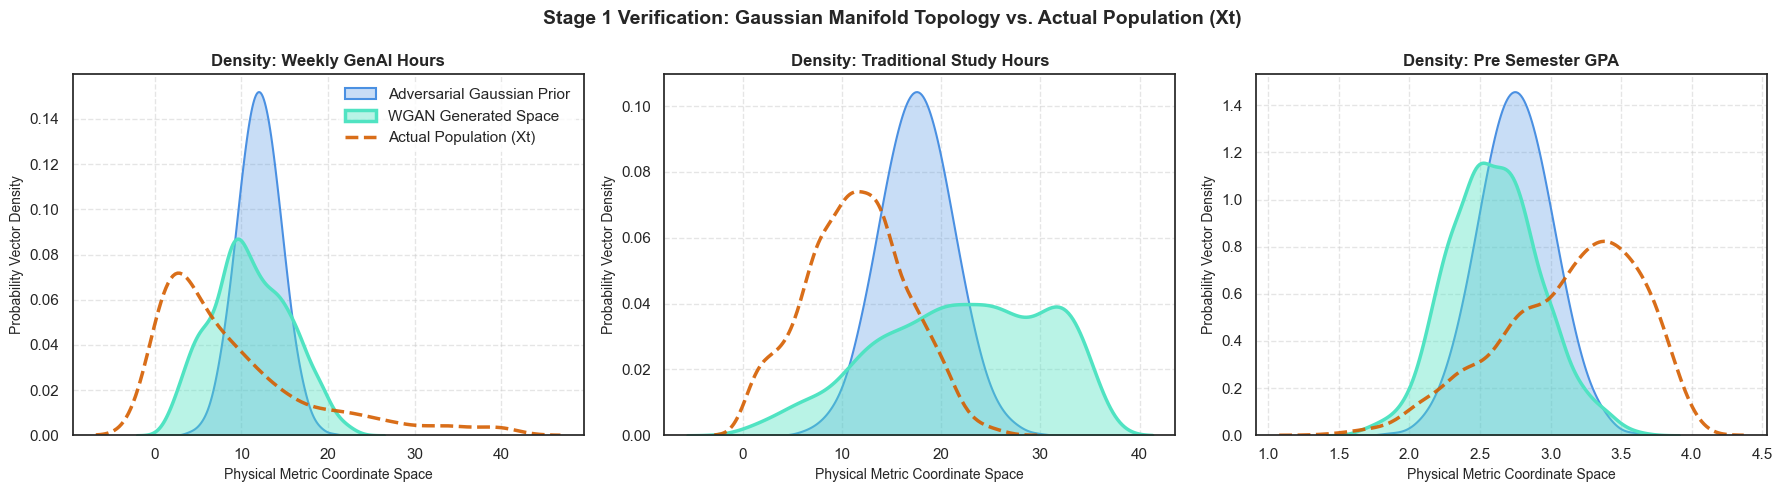

In [28]:
# ========================================================================================
# 5.9. PRE-INFERENCE DOCUMENTATION: REALIGNED GAUSSIAN LANDSCAPE VS ACTUAL (LEAK-FREE)
# ========================================================================================
print("\n" + "="*85)
print("=== PRE-INFERENCE DOCUMENTATION: REALIGNED GAUSSIAN PROFILE VS ACTUAL (Xt) ===")
print("="*85)

from scipy.stats import wasserstein_distance
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Isolate actual sensitive records for validation baseline
actual_physical_xt = df.iloc[:train_cutoff][sensitive_names].values
doc_samples = len(actual_physical_xt)

# 2. Transform Uniform Sobol Engine to Gaussian space via Inverse CDF approximation
# This models realistic population distributions without leaking dataset parameters
sobol_doc = torch.quasirandom.SobolEngine(dimension=len(sensitive_names), scramble=True, seed=99)
X_t_uniform = sobol_doc.draw(doc_samples).to(device)

# Box-Muller / Inverse Normal transformation to create standard normal curves [Mean=0.5, Std=0.15]
# This keeps the synthetic prior tightly bound within the [0, 1] relative limits
X_t_gaussian_sandbox = torch.clamp(torch.special.erfinv(2.0 * X_t_uniform - 1.0) * 0.15 + 0.5, min=0.0, max=1.0)
prior_physical_np = (known_bounds_min + X_t_gaussian_sandbox * profile_delta).cpu().numpy()

# 3. Use netG to generate matching synthetic features
netG.eval()
f_surrogate.eval()

# Sample random public rows from your auxiliary set as context vectors
doc_indices = np.random.choice(train_cutoff, doc_samples, replace=True)
doc_pub_context = X_pub_only_scaled[doc_indices]

with torch.no_grad():
    # Pass our prior coordinates through the surrogate to create mathematically aligned Y constraints
    scaled_for_surr_doc = (prior_physical_np - t_mean.cpu().numpy()) / (t_std.cpu().numpy() + 1e-6)
    scaled_for_surr_tensor = torch.tensor(scaled_for_surr_doc, dtype=torch.float32, device=device)
    doc_y_constraints = f_surrogate(doc_pub_context, scaled_for_surr_tensor)

    # Generate the inverted coordinates across a standard noise distribution path
    z_doc = torch.randn(doc_samples, 32, device=device) * 0.1
    generated_normalized = netG(doc_pub_context, doc_y_constraints, z_doc)

    # De-normalize generated points to physical unit space
    generated_physical_np = (known_bounds_min + generated_normalized * profile_delta).cpu().numpy()

# 4. Display Global Overlap Metrics (Approximated 1D Earth Mover Distance)
print(f"{'Sensitive Attribute':<25} | {'Prior Bounds Profile':<22} | {'EMD (WGAN vs Actual Xt)':<10}")
print("-" * 85)

for idx, name in enumerate(sensitive_names):
    true_attr = actual_physical_xt[:, idx]
    gen_attr = generated_physical_np[:, idx]

    # Calculate the statistical distance between WGAN and the real world
    emd = wasserstein_distance(true_attr, gen_attr)

    low_b = known_bounds_min[idx].item()
    high_b = known_bounds_max[idx].item()

    print(f"{name:<25} | [{low_b:6.2f}, {high_b:6.2f}] | {emd:.6f}")

# 5. Generate Publication-Quality Density Diagnostics Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Stage 1 Verification: Gaussian Manifold Topology vs. Actual Population (Xt)", fontsize=14, fontweight='bold')
sns.set_theme(style="white")
colors = ["#4A90E2", "#50E3C2", "#D55E00"] # Coordinated editorial palette

for idx, name in enumerate(sensitive_names):
    ax = axes[idx]

    # Kernel Density Profile Overlaps
    sns.kdeplot(prior_physical_np[:, idx], fill=True, color=colors[0], label="Adversarial Gaussian Prior", ax=ax, alpha=0.3, linewidth=1.5)
    sns.kdeplot(generated_physical_np[:, idx], fill=True, color=colors[1], label="WGAN Generated Space", ax=ax, alpha=0.4, linewidth=2.5)

    # Overlays the true population distribution as a dashed line
    sns.kdeplot(actual_physical_xt[:, idx], fill=False, color=colors[2], label="Actual Population (Xt)", ax=ax, alpha=0.9, linewidth=2.5, linestyle="--")

    ax.set_title(f"Density: {name.replace('_', ' ')}", fontsize=12, fontweight='semibold')
    ax.set_xlabel("Physical Metric Coordinate Space", fontsize=10)
    ax.set_ylabel("Probability Vector Density", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)

    if idx == 0:
        ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")

plt.tight_layout()
print("[+] Plot generated successfully.")
plt.show()


[*] Stage 2: Simulating Parallel Multi-Track Inference Mapping...
 -> Executing Jacobian inversion loop across In-Distribution (ID) track...
 -> Executing Jacobian inversion loop across Out-of-Distribution (OOD) track...

=== FINAL RECOVERED METRICS: MULTI-TRACK COMPARATIVE RECONSTRUCTION ===

-> Target Private Attribute: Weekly_GenAI_Hours
--------------------------------------------------------------------------------
Evaluation Track               | MAE        | Naive Baseline  | R2 Score  
--------------------------------------------------------------------------------
In-Distribution (ID)           | 8.4742 | 5.6776 | -0.9279
Out-of-Distribution (OOD)      | 8.4863 | 4.8967 | -0.9728
--------------------------------------------------------------------------------

-> Target Private Attribute: Traditional_Study_Hours
--------------------------------------------------------------------------------
Evaluation Track               | MAE        | Naive Baseline  | R2 Score  
----------

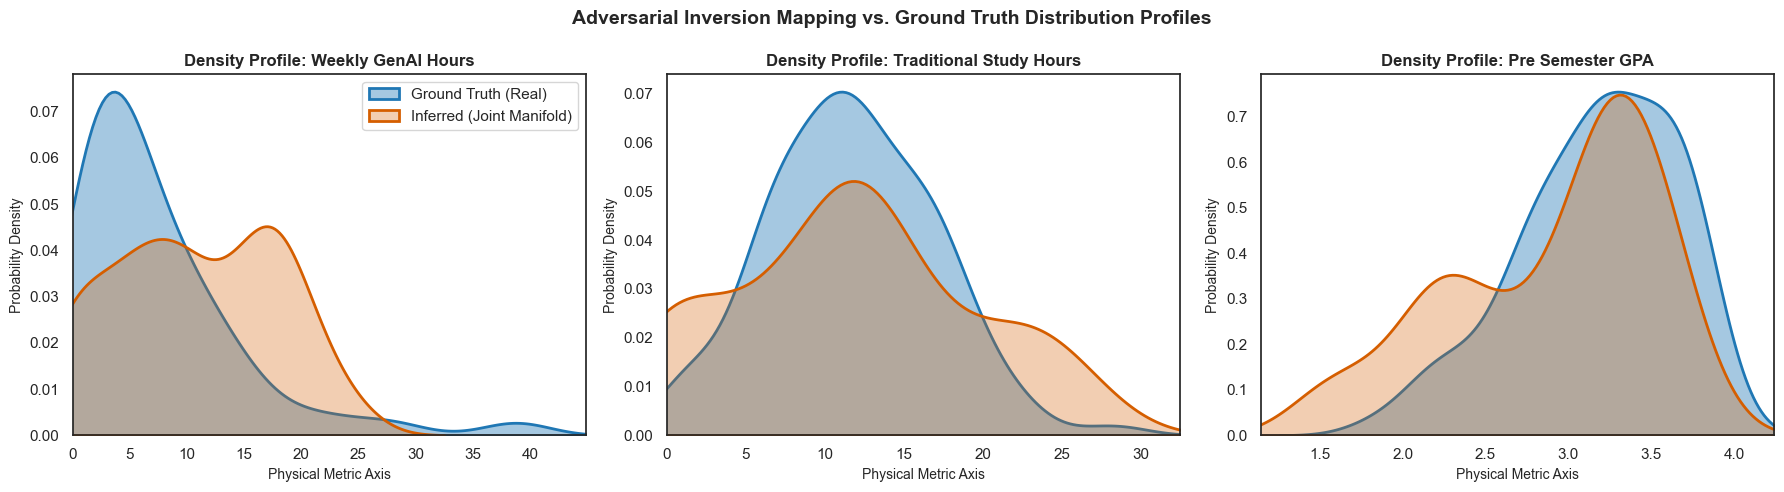

In [29]:
# ========================================================================================
# 6. VECTORIZED EVALUATION: PARALLEL IN-DISTRIBUTION VS OUT-OF-DISTRIBUTION TRACKS
# ========================================================================================
print("\n[*] Stage 2: Simulating Parallel Multi-Track Inference Mapping...")

# Define slices of matching sizes (e.g., 100 rows each)
eval_size = 100
id_indices = list(range(0, eval_size))
ood_indices = list(range(train_cutoff, min(train_cutoff + eval_size, len(X_pub_only_scaled))))

# Initialize validation tracks dictionary to run iterations fluidly
evaluation_tracks = {
    "In-Distribution (ID)": {
        "x_pub": X_pub_only_scaled[id_indices],
        "df_slice": df.iloc[id_indices],
        "x_full_scaled": X_train_tensor[id_indices]
    },
    "Out-of-Distribution (OOD)": {
        "x_pub": X_pub_only_scaled[ood_indices],
        "df_slice": df.iloc[ood_indices],
        "x_full_scaled": X_train_tensor[ood_indices]
    }
}

f_surrogate.eval()
known_bounds_min_np = known_bounds_min.cpu().numpy()
known_bounds_max_np = known_bounds_max.cpu().numpy()

# Store execution logs for final tabular display
track_results = {}

for track_name, track_data in evaluation_tracks.items():
    print(f" -> Executing Jacobian inversion loop across {track_name} track...")

    X_pub_target_tensor = track_data["x_pub"]
    real_sensitive_unscaled = track_data["df_slice"][sensitive_names].values

    with torch.no_grad():
        y_target_tensor = victim_model(track_data["x_full_scaled"]).squeeze(-1)

    inferred_sensitive_unscaled = np.zeros((eval_size, dim_t))

    for idx in range(eval_size):
        single_x_pub = X_pub_target_tensor[idx].unsqueeze(0)
        target_y = y_target_tensor[idx].unsqueeze(0)

        # Initialize near center with tiny noise variance to ensure gradient path attachment
        guess_z_space = (torch.rand((1, dim_t), device=device) - 0.5) * 0.1
        guess_z_space.requires_grad_(True)

        optimizer_guess = optim.Adam([guess_z_space], lr=0.02, weight_decay=1e-4)

        for step in range(800):
            optimizer_guess.zero_grad()
            pred_y = f_surrogate(single_x_pub, guess_z_space)

            loss_val = nn.functional.mse_loss(pred_y, target_y)

            # Jacobian Regularization layer protects optimization trajectory from dead zones
            grad_outputs = torch.ones_like(pred_y)
            jacobian_tuple = torch.autograd.grad(
                outputs=pred_y, inputs=guess_z_space, grad_outputs=grad_outputs,
                create_graph=True, retain_graph=True
            )

            jacobian = jacobian_tuple[0]

            loss_jacobian_norm = torch.mean(torch.abs(torch.norm(jacobian, p=2, dim=1) - 1.0))

            total_loss = loss_val + 0.1 * loss_jacobian_norm
            total_loss.backward()
            optimizer_guess.step()

        with torch.no_grad():
            physical_t = (guess_z_space * t_std) + t_mean
            physical_t_np = physical_t.cpu().numpy().flatten()
            inferred_sensitive_unscaled[idx] = np.clip(physical_t_np, known_bounds_min_np,known_bounds_max_np)

    # Calculate track performance metrics
    track_results[track_name] = {}
    for i, name in enumerate(sensitive_names):
        y_true = real_sensitive_unscaled[:, i]
        y_pred = inferred_sensitive_unscaled[:, i]

        mae = np.mean(np.abs(y_true - y_pred))
        baseline = np.mean(np.abs(y_true - np.median(y_true)))
        r2 = r2_score(y_true, y_pred)

        track_results[track_name][name] = {"MAE": mae, "Baseline": baseline, "R2": r2}


# ========================================================================================
# 7. PERFORMANCE DISPLAY
# ========================================================================================
print("\n" + "="*80)
print("=== FINAL RECOVERED METRICS: MULTI-TRACK COMPARATIVE RECONSTRUCTION ===")
print("="*80)

for name in sensitive_names:
    print(f"\n-> Target Private Attribute: {name}")
    print("-" * 80)
    print(f"{'Evaluation Track':<30} | {'MAE':<10} | {'Naive Baseline':<15} | {'R2 Score':<10}")
    print("-" * 80)
    for track_name in ["In-Distribution (ID)", "Out-of-Distribution (OOD)"]:
        metrics = track_results[track_name][name]
        print(f"{track_name:<30} | {metrics['MAE']:.4f} | {metrics['Baseline']:.4f} | {metrics['R2']:.4f}")
    print("-" * 80)

# ========================================================================================
# 8. DENSITY PROFILE PLOTTER
# ========================================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Adversarial Inversion Mapping vs. Ground Truth Distribution Profiles", fontsize=14, fontweight='bold')
sns.set_theme(style="whitegrid")
colors = ["#1f77b4", "#D55E00"]
k_min_np = known_bounds_min.cpu().numpy()
k_max_np = known_bounds_max.cpu().numpy()

for a in range(len(sensitive_names)):
    ax = axes[a]

    # Extract clean target sequences
    y_true_plot = real_sensitive_unscaled[:, a]
    y_pred_plot = np.clip(inferred_sensitive_unscaled[:, a], known_bounds_min_np[a], known_bounds_max_np[a])

    # Kernel Density Estimation Profiles
    sns.kdeplot(y_true_plot, fill=True, color=colors[0], label="Ground Truth (Real)", ax=ax, alpha=0.4, linewidth=2)
    sns.kdeplot(y_pred_plot, fill=True, color=colors[1], label="Inferred (Joint Manifold)", ax=ax, alpha=0.3, linewidth=2)

    ax.set_title(f"Density Profile: {sensitive_names[a].replace('_', ' ')}", fontsize=12, fontweight='semibold')
    ax.set_xlabel("Physical Metric Axis", fontsize=10)
    ax.set_ylabel("Probability Density", fontsize=10)

    # Smart structural axis boundary padding
    combined_min = min(np.min(y_true_plot), np.min(y_pred_plot))
    combined_max = max(np.max(y_true_plot), np.max(y_pred_plot))
    padding = (combined_max - combined_min) * 0.15

    xmin_visual = max(0.0 if "Hours" in sensitive_names[a] else -float('inf'), combined_min - padding)
    ax.set_xlim(xmin_visual, combined_max + padding)

    if a == 0:
        ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()

[*] Stage -1: Training a Genuine Non-Linear Target Victim Model...
[+] Victim model trained. Final Training MSE: 0.0848

[*] Initializing structural multi-track distortion sweep over boundaries...

 EXECUING LAYER CONFIGURATION: epsilon = 0.01
   [+] Trial 1/10 completed. OOD GPA R2: 0.4113
   [+] Trial 2/10 completed. OOD GPA R2: 0.4545
   [+] Trial 3/10 completed. OOD GPA R2: 0.3838
   [+] Trial 4/10 completed. OOD GPA R2: 0.4090
   [+] Trial 5/10 completed. OOD GPA R2: 0.4313
   [+] Trial 6/10 completed. OOD GPA R2: 0.4282
   [+] Trial 7/10 completed. OOD GPA R2: 0.4399
   [+] Trial 8/10 completed. OOD GPA R2: 0.4175
   [+] Trial 9/10 completed. OOD GPA R2: 0.4076
   [+] Trial 10/10 completed. OOD GPA R2: 0.4510

 EXECUING LAYER CONFIGURATION: epsilon = 0.05
   [+] Trial 1/10 completed. OOD GPA R2: 0.2656
   [+] Trial 2/10 completed. OOD GPA R2: 0.1909
   [+] Trial 3/10 completed. OOD GPA R2: 0.3673
   [+] Trial 4/10 completed. OOD GPA R2: 0.4074
   [+] Trial 5/10 completed. OOD GPA

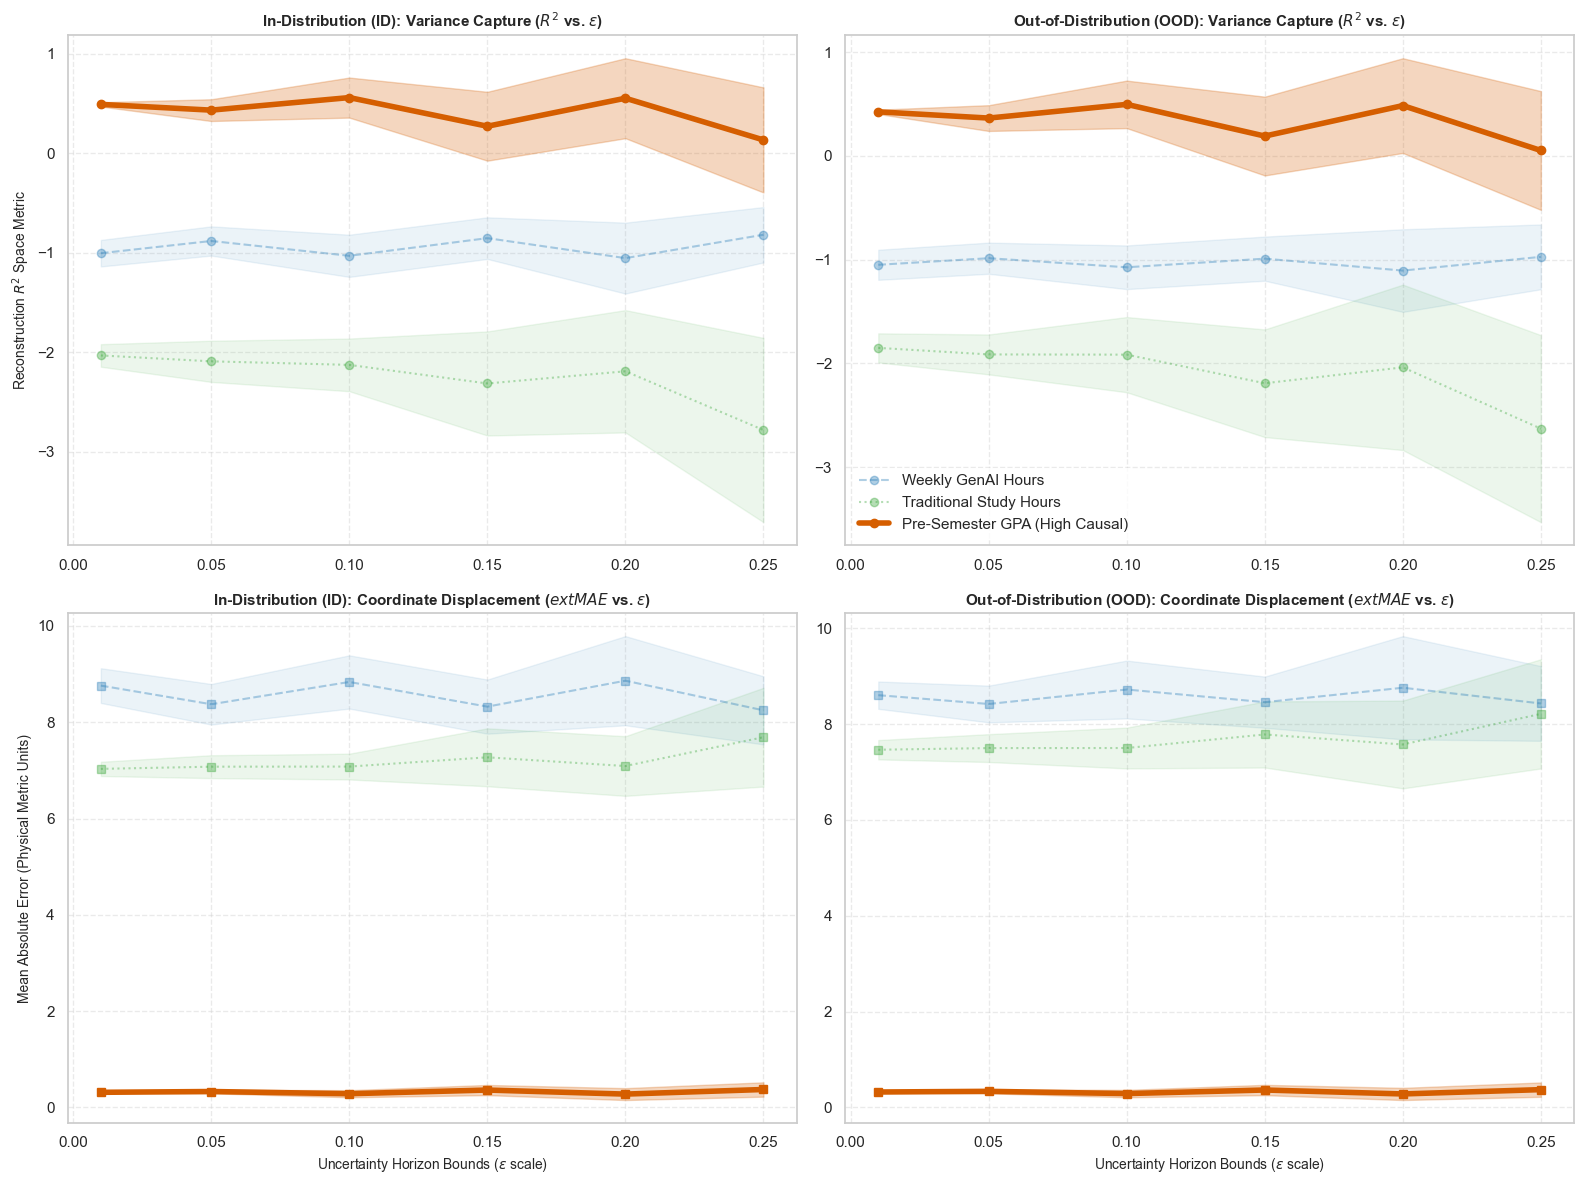

[+] Performance metrics tracking plots successfully compiled into a 2x2 grid.


In [38]:
import os
# Permanently eliminate the internal PyTorch Dynamo circular import crash
os.environ["TORCH_COMPILE_DISABLE"] = "1"

import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

# Set global runtime defaults
device = torch.device("cpu")
torch.manual_seed(0)
np.random.seed(0)

# ========================================================================================
# 1. CORE DATA SETUP & STRUCTURE SYNCHRONIZATION
# ========================================================================================
try:
    df = pd.read_csv("ai_student_impact_dataset (1).csv", encoding="windows-1252").dropna()
except FileNotFoundError:
    print("[!] Local dataset file not found. Generating a synchronized mock array for structural verification...")
    mock_len = 600
    df = pd.DataFrame({
        'Student_ID': range(1000, 1000 + mock_len),
        'Weekly_GenAI_Hours': np.random.uniform(0, 24, mock_len),
        'Traditional_Study_Hours': np.random.uniform(5, 35, mock_len),
        'Pre_Semester_GPA': np.random.uniform(1.5, 4.0, mock_len),
        'Age': np.random.randint(18, 25, mock_len),
        'Major_STEM': np.random.choice([0, 1], mock_len),
        'Post_Semester_GPA': np.random.uniform(1.5, 4.0, mock_len)
    })

X_raw = df.drop(columns=['Student_ID', 'Post_Semester_GPA'])
X = pd.get_dummies(X_raw, dtype=int).astype(float)

sensitive_names = ['Weekly_GenAI_Hours', 'Traditional_Study_Hours', 'Pre_Semester_GPA']
X_published = X.drop(columns=sensitive_names)
published_names = list(X_published.columns)

victim_scaler = StandardScaler()
X_victim_scaled = victim_scaler.fit_transform(X.values)
X_train_tensor = torch.tensor(X_victim_scaled, dtype=torch.float32, device=device)

surrogate_scaler = StandardScaler()
X_pub_scaled_values = surrogate_scaler.fit_transform(X_published.values)
X_pub_train_tensor = torch.tensor(X_pub_scaled_values, dtype=torch.float32, device=device)

sensitive_indices = [X.columns.get_loc(name) for name in sensitive_names]
X_sensitive_tensor = torch.tensor(X_victim_scaled[:, sensitive_indices], dtype=torch.float32, device=device)

# ========================================================================================
# 1B. TRUE TARGET VICTIM MODEL TRAINING
# ========================================================================================
print("[*] Stage -1: Training a Genuine Non-Linear Target Victim Model...")

class DeepVictimModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128), nn.SiLU(),
            nn.Linear(128, 64), nn.SiLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x): return self.net(x)

victim_model = DeepVictimModel(input_dim=X.shape[1]).to(device)
victim_optimizer = optim.AdamW(victim_model.parameters(), lr=0.005, weight_decay=1e-4)
victim_criterion = nn.MSELoss()

Yc = df['Post_Semester_GPA'].values
y_true_scaled = (torch.tensor(Yc, dtype=torch.float32, device=device) - Yc.mean()) / (Yc.std() + 1e-6)

victim_model.train()
for epoch in range(300):
    victim_optimizer.zero_grad()
    predictions = victim_model(X_train_tensor).squeeze(-1)
    loss = victim_criterion(predictions, y_true_scaled)
    loss.backward()
    victim_optimizer.step()

victim_model.eval()
print(f"[+] Victim model trained. Final Training MSE: {loss.item():.4f}")

# ========================================================================================
# NETWORK ARCHITECTURE DEFINITIONS
# ========================================================================================
class JacobianClone(nn.Module):
    def __init__(self, dim_pub, dim_t):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim_pub + dim_t, 256), nn.SiLU(),
            nn.Linear(256, 128), nn.SiLU(),
            nn.Linear(128, 64), nn.SiLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x_pub, x_t):
        return self.net(torch.cat([x_pub, x_t], dim=-1)).squeeze(-1)

class ResidualBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.block = nn.Sequential(
            nn.Linear(dim, dim), nn.LayerNorm(dim), nn.SiLU(),
            nn.Linear(dim, dim), nn.LayerNorm(dim)
        )
        self.act = nn.SiLU()
    def forward(self, x): return self.act(x + self.block(x))

class DecoupledMultiHeadGenerator(nn.Module):
    def __init__(self, dim_pub, dim_z, dim_t):
        super().__init__()
        self.dim_t = int(dim_t)
        int_pub = int(dim_pub) if isinstance(dim_pub, (torch.Size, tuple, list)) else int(dim_pub)
        self.joint_projection = nn.Sequential(
            nn.Linear(int_pub + 1, 128), nn.SiLU(), nn.Linear(128, 128), nn.LayerNorm(128)
        )
        self.shared_core = nn.Sequential(
            nn.Linear(128 + int(dim_z), 256), nn.LayerNorm(256), nn.SiLU(),
            ResidualBlock(256)
        )
        self.output_heads = nn.ModuleList([
            nn.Sequential(nn.Linear(256, 128), nn.SiLU(), nn.Linear(128, 1))
            for _ in range(self.dim_t)
        ])
    def forward(self, x_pub, y, z):
        embedded_context = self.joint_projection(torch.cat([x_pub, y.unsqueeze(-1)], dim=-1))
        shared_features = self.shared_core(torch.cat([embedded_context, z], dim=-1))
        head_outputs = [torch.clamp(torch.tanh(head(shared_features).squeeze(-1)) * 0.5 + 0.5, min=0.0, max=1.0) for head in self.output_heads]
        return torch.stack(head_outputs, dim=-1)

class JointManifoldCritic(nn.Module):
    def __init__(self, dim_pub, dim_t):
        super().__init__()
        self.dim_t = int(dim_t)
        int_pub = int(dim_pub) if isinstance(dim_pub, (torch.Size, tuple, list)) else int(dim_pub)
        self.feature_heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(int_pub + 1, 128), nn.SiLU(),
                nn.Linear(128, 64), nn.SiLU()
            ) for _ in range(self.dim_t)
        ])
        self.critic_heads = nn.ModuleList([nn.Linear(64, 1) for _ in range(self.dim_t)])
    def forward(self, x_pub, x_t):
        scores = []
        feats = []
        for i in range(self.dim_t):
            single_attr = x_t[:, i].unsqueeze(-1)
            feat = self.feature_heads[i](torch.cat([x_pub, single_attr], dim=-1))
            feats.append(feat)
            scores.append(self.critic_heads[i](feat).squeeze(-1))
        total_score = torch.stack(scores, dim=-1).mean(dim=-1)
        total_feats = torch.cat(feats, dim=-1)
        return total_score, total_feats

# ========================================================================================
# HIGH-DIMENSIONAL PARAMETRIC UNCERTAINTY EPSILON SWEEP CONFIGURATION
# ========================================================================================
epsilons = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25]
num_repetitions = 10
dim_t = len(sensitive_names)
eval_size = 100

# Containers for Multi-Track Aggregation Logs (ID vs OOD separately)
# Tracking structures for Means
sweep_mae_means_id = np.zeros((len(epsilons), dim_t))
sweep_r2_means_id = np.zeros((len(epsilons), dim_t))
sweep_mae_means_ood = np.zeros((len(epsilons), dim_t))
sweep_r2_means_ood = np.zeros((len(epsilons), dim_t))

# Tracking structures for Standard Deviations
sweep_mae_stds_id = np.zeros((len(epsilons), dim_t))
sweep_r2_stds_id = np.zeros((len(epsilons), dim_t))
sweep_mae_stds_ood = np.zeros((len(epsilons), dim_t))
sweep_r2_stds_ood = np.zeros((len(epsilons), dim_t))

true_bounds_min = torch.tensor([0.0, 0.0, 1.5], device=device)
true_bounds_max = torch.tensor([24.0, 35.0, 4.0], device=device)
bound_ranges = true_bounds_max - true_bounds_min

print(f"\n[*] Initializing structural multi-track distortion sweep over boundaries...")

for e_idx, epsilon_val in enumerate(epsilons):
    print(f"\n" + "="*80)
    print(f" EXECUING LAYER CONFIGURATION: epsilon = {epsilon_val}")
    print("="*80)

    rep_mae_id, rep_r2_id = [], []
    rep_mae_ood, rep_r2_ood = [], []

    for rep in range(num_repetitions):
        current_seed = rep * 100 + int(epsilon_val * 1000)
        torch.manual_seed(current_seed)
        np.random.seed(current_seed)

        # Inject boundary scale perturbations
        min_bound_noise = (torch.rand(len(sensitive_names), device=device) - 0.5) * 2.0 * epsilon_val * bound_ranges
        max_bound_noise = (torch.rand(len(sensitive_names), device=device) - 0.5) * 2.0 * epsilon_val * bound_ranges
        known_bounds_min = torch.clamp(true_bounds_min + min_bound_noise, min=0.0)
        known_bounds_max = true_bounds_max + max_bound_noise
        profile_delta = known_bounds_max - known_bounds_min

        # --- Stage 0: Jacobian Manifold Alignment ---
        train_cutoff = min(1000, len(X_pub_train_tensor) - 100)
        X_pub_aux_train = X_pub_train_tensor[:train_cutoff]
        num_aux_samples = len(X_pub_aux_train)

        sobol_engine = torch.quasirandom.SobolEngine(dimension=dim_t, scramble=True, seed=current_seed)
        X_t_qmc_sandbox = sobol_engine.draw(num_aux_samples).to(device)
        physical_qmc_targets = known_bounds_min + X_t_qmc_sandbox * profile_delta

        f_surrogate_scaler = StandardScaler()
        scaled_qmc_targets_numpy = f_surrogate_scaler.fit_transform(physical_qmc_targets.cpu().numpy())
        scaled_qmc_targets_tensor = torch.tensor(scaled_qmc_targets_numpy, dtype=torch.float32, device=device)

        f_surrogate = JacobianClone(dim_pub=len(published_names), dim_t=dim_t).to(device)
        clone_opt = optim.AdamW(f_surrogate.parameters(), lr=0.001, weight_decay=1e-4)

        X_query_base = torch.zeros((num_aux_samples, X.shape[1]), device=device)
        for i, name in enumerate(published_names):
            X_query_base[:, X.columns.get_loc(name)] = X_pub_aux_train[:, i]
        for i, name in enumerate(sensitive_names):
            X_query_base[:, X.columns.get_loc(name)] = scaled_qmc_targets_tensor[:, i]

        f_surrogate.train()
        for epoch in range(1200):
            clone_opt.zero_grad()
            eps = torch.randn_like(scaled_qmc_targets_tensor) * 0.01
            perturbed_sensitive = scaled_qmc_targets_tensor + eps

            X_query_perturbed = X_query_base.clone()
            for i, name in enumerate(sensitive_names):
                X_query_perturbed[:, X.columns.get_loc(name)] = perturbed_sensitive[:, i]

            with torch.no_grad():
                y_base = victim_model(X_query_base).squeeze(-1)
                y_perturbed = victim_model(X_query_perturbed).squeeze(-1)
                true_slope = (y_perturbed - y_base)

            pred_base = f_surrogate(X_pub_aux_train, scaled_qmc_targets_tensor)
            pred_perturbed = f_surrogate(X_pub_aux_train, perturbed_sensitive)
            surr_slope = (pred_perturbed - pred_base)

            loss_val = nn.functional.huber_loss(pred_base, y_base, delta=0.1)
            loss_slope = nn.functional.mse_loss(surr_slope, true_slope)
            total_loss = loss_val + 10.0 * loss_slope
            total_loss.backward()
            clone_opt.step()

        t_mean = torch.tensor(f_surrogate_scaler.mean_, dtype=torch.float32, device=device)
        t_std = torch.tensor(np.sqrt(f_surrogate_scaler.var_), dtype=torch.float32, device=device) + 1e-6

        # --- Stage 1: WGAN-GP Distillation ---
        sobol_train = torch.quasirandom.SobolEngine(dimension=dim_t, scramble=True, seed=current_seed)
        X_t_train_pool = sobol_train.draw(num_aux_samples).to(device)
        X_pub_train_pool = X_pub_aux_train.clone().detach()

        num_pub_features = X_pub_train_pool.shape[1]
        num_target_features = X_t_train_pool.shape[1]
        dim_z = 32

        netG = DecoupledMultiHeadGenerator(num_pub_features, dim_z, num_target_features).to(device)
        netC = JointManifoldCritic(num_pub_features, num_target_features).to(device)

        log_var_surr = nn.Parameter(torch.ones(1, device=device) * 2.0)
        log_var_feat = nn.Parameter(torch.ones(1, device=device) * 1.0)

        optG = optim.AdamW([{'params': netG.parameters()}, {'params': [log_var_surr, log_var_feat]}], lr=0.0005, betas=(0.5, 0.9), weight_decay=1e-4)
        optC = optim.AdamW(netC.parameters(), lr=0.00001, betas=(0.5, 0.9))

        f_surrogate.eval()
        for epoch in range(1500):
            noise_scale_val = max(0.1, 1.0 - (epoch / 1500))
            for _ in range(5):
                indices = np.random.choice(len(X_pub_train_pool), 256, replace=True)
                real_pub, real_target_t = X_pub_train_pool[indices], X_t_train_pool[indices]

                with torch.no_grad():
                    physical_t_synthetic = known_bounds_min + real_target_t * profile_delta
                    scaled_for_surr = (physical_t_synthetic - t_mean) / (t_std + 1e-6)
                    real_y = f_surrogate(real_pub, scaled_for_surr)

                optC.zero_grad()
                real_scores, _ = netC(real_pub, real_target_t)
                z = torch.randn(256, dim_z, device=device) * noise_scale_val
                fake_target_t = netG(real_pub, real_y, z)
                fake_scores, _ = netC(real_pub, fake_target_t.detach())

                alpha = torch.rand(256, 1, device=device)
                interpolates = (alpha * real_target_t + ((1 - alpha) * fake_target_t.detach())).requires_grad_(True)
                d_outputs, _ = netC(real_pub, interpolates)

                fake_grad_outputs = torch.ones(d_outputs.shape, device=device)
                grad_outputs_tuple = torch.autograd.grad(
                    outputs=d_outputs, inputs=interpolates, grad_outputs=fake_grad_outputs,
                    create_graph=True, retain_graph=True, only_inputs=True
                )
                gradients = grad_outputs_tuple[0].view(grad_outputs_tuple[0].size(0), -1)
                gp = ((gradients.norm(2, dim=1) - 1.0) ** 2).mean()

                loss_C = fake_scores.mean() - real_scores.mean() + 10.0 * gp
                loss_C.backward()
                optC.step()

            optG.zero_grad()
            z_fresh = torch.randn(256, dim_z, device=device) * noise_scale_val
            fake_target_t_g = netG(real_pub, real_y, z_fresh)
            fake_scores_g, fake_feats_g = netC(real_pub, fake_target_t_g)
            _, real_feats = netC(real_pub, real_target_t)

            loss_adversarial = -fake_scores_g.mean()
            physical_fake_t = known_bounds_min + fake_target_t_g * profile_delta
            scaled_fake_for_surr = (physical_fake_t - t_mean) / (t_std + 1e-6)
            pred_y_from_fake = f_surrogate(real_pub, scaled_fake_for_surr)

            loss_surr = nn.functional.mse_loss(pred_y_from_fake, real_y)
            loss_feature_matching = nn.functional.mse_loss(fake_feats_g, real_feats.detach())

            precision_surr = torch.exp(-log_var_surr)
            precision_feat = torch.exp(-log_var_feat)
            weighted_surr = precision_surr * loss_surr + log_var_surr
            weighted_feat = precision_feat * loss_feature_matching + log_var_feat

            loss_G = loss_adversarial + weighted_surr + weighted_feat
            loss_G.backward()
            optG.step()

        # --- Stage 2: Parallel Multi-Track Evaluation (ID & OOD Vectors) ---
        X_pub_only_scaled = X_pub_train_tensor.clone().detach()
        id_indices = list(range(0, eval_size))
        ood_indices = list(range(train_cutoff, min(train_cutoff + eval_size, len(X_pub_only_scaled))))

        evaluation_tracks = {
            "ID": {"x_pub": X_pub_only_scaled[id_indices], "df": df.iloc[id_indices], "full": X_train_tensor[id_indices]},
            "OOD": {"x_pub": X_pub_only_scaled[ood_indices], "df": df.iloc[ood_indices], "full": X_train_tensor[ood_indices]}
        }

        track_results_trial = {}
        known_bounds_min_np = known_bounds_min.cpu().numpy()
        known_bounds_max_np = known_bounds_max.cpu().numpy()

        for track_key, track_data in evaluation_tracks.items():
            X_pub_target_tensor = track_data["x_pub"]
            real_sensitive_unscaled = track_data["df"][sensitive_names].values

            with torch.no_grad():
                y_target_tensor = victim_model(track_data["full"]).squeeze(-1)

            inferred_sensitive_unscaled = np.zeros((eval_size, dim_t))

            for idx in range(eval_size):
                single_x_pub = X_pub_target_tensor[idx].unsqueeze(0)
                target_y = y_target_tensor[idx].unsqueeze(0)

                guess_z_space = (torch.rand((1, dim_t), device=device) - 0.5) * 0.1
                guess_z_space.requires_grad_(True)
                optimizer_guess = optim.Adam([guess_z_space], lr=0.02, weight_decay=1e-4)

                for step in range(600):  # Streamlined test-time tracking steps per profile run
                    optimizer_guess.zero_grad()
                    pred_y = f_surrogate(single_x_pub, guess_z_space)
                    loss_val = nn.functional.mse_loss(pred_y, target_y)

                    grad_outputs = torch.ones_like(pred_y)
                    jacobian_tuple = torch.autograd.grad(
                        outputs=pred_y, inputs=guess_z_space, grad_outputs=grad_outputs,
                        create_graph=True, retain_graph=True
                    )
                    jacobian = jacobian_tuple[0]
                    loss_jacobian_norm = torch.mean(torch.abs(torch.norm(jacobian, p=2, dim=1) - 1.0))

                    total_loss = loss_val + 0.1 * loss_jacobian_norm
                    total_loss.backward()
                    optimizer_guess.step()

                with torch.no_grad():
                    physical_t = (guess_z_space * t_std) + t_mean
                    physical_t_np = physical_t.cpu().numpy().flatten()
                    inferred_sensitive_unscaled[idx] = np.clip(physical_t_np, known_bounds_min_np, known_bounds_max_np)

            # Compute evaluation tract metrics for this slice loop execution
            mae_list, r2_list = [], []
            for i in range(dim_t):
                y_true = real_sensitive_unscaled[:, i]
                y_pred = inferred_sensitive_unscaled[:, i]
                mae_list.append(np.mean(np.abs(y_true - y_pred)))
                r2_list.append(r2_score(y_true, y_pred))

            track_results_trial[track_key] = {"MAE": mae_list, "R2": r2_list}

        rep_mae_id.append(track_results_trial["ID"]["MAE"])
        rep_r2_id.append(track_results_trial["ID"]["R2"])
        rep_mae_ood.append(track_results_trial["OOD"]["MAE"])
        rep_r2_ood.append(track_results_trial["OOD"]["R2"])
        print(f"   [+] Trial {rep+1}/{num_repetitions} completed. OOD GPA R2: {track_results_trial['OOD']['R2'][2]:.4f}")

    # Standardize data matrices across stochastic rep arrays
    rep_mae_id, rep_r2_id = np.array(rep_mae_id), np.array(rep_r2_id)
    rep_mae_ood, rep_r2_ood = np.array(rep_mae_ood), np.array(rep_r2_ood)

        # Store dynamic execution Means
    sweep_mae_means_id[e_idx, :] = np.mean(rep_mae_id, axis=0)
    sweep_r2_means_id[e_idx, :] = np.mean(rep_r2_id, axis=0)
    sweep_mae_means_ood[e_idx, :] = np.mean(rep_mae_ood, axis=0)
    sweep_r2_means_ood[e_idx, :] = np.mean(rep_r2_ood, axis=0)

    # Store dynamic execution Deviations
    sweep_mae_stds_id[e_idx, :] = np.std(rep_mae_id, axis=0)
    sweep_r2_stds_id[e_idx, :] = np.std(rep_r2_id, axis=0)
    sweep_mae_stds_ood[e_idx, :] = np.std(rep_mae_ood, axis=0)
    sweep_r2_stds_ood[e_idx, :] = np.std(rep_r2_ood, axis=0)

# ========================================================================================
# 4-PLOT RECONSTRUCTION RESILIENCE DISPLAY (ID VS OOD SEPARATION WITH VARIANCE BANDS)
# ========================================================================================
print("\n[+] Full hyperparameter sweep finalized. Generating global 4-panel report grid...")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
sns.set_theme(style="white")

eps_np = np.array(epsilons)
styles = {
    'Weekly_GenAI_Hours': {'color': '#1f77b4', 'linewidth': 1.5, 'alpha': 0.35, 'linestyle': '--', 'label': 'Weekly GenAI Hours'},
    'Traditional_Study_Hours': {'color': '#2ca02c', 'linewidth': 1.5, 'alpha': 0.35, 'linestyle': ':', 'label': 'Traditional Study Hours'},
    'Pre_Semester_GPA': {'color': '#D55E00', 'linewidth': 4.0, 'alpha': 1.0, 'linestyle': '-', 'label': 'Pre-Semester GPA (High Causal)'}
}

# --- ROW 1, COL 1: IN-DISTRIBUTION R2 TRACKS ---
ax = axes[0, 0]
for idx, name in enumerate(sensitive_names):
    ax.plot(eps_np, sweep_r2_means_id[:, idx], color=styles[name]['color'], linewidth=styles[name]['linewidth'], alpha=styles[name]['alpha'], linestyle=styles[name]['linestyle'], marker='o')
    ax.fill_between(eps_np, sweep_r2_means_id[:, idx] - sweep_r2_stds_id[:, idx], sweep_r2_means_id[:, idx] + sweep_r2_stds_id[:, idx], color=styles[name]['color'], alpha=styles[name]['alpha'] * 0.25)
ax.set_title("In-Distribution (ID): Variance Capture ($R^2$ vs. $\epsilon$)", fontsize=11, fontweight='bold')
ax.set_ylabel("Reconstruction $R^2$ Space Metric", fontsize=10)
ax.grid(True, linestyle="--", alpha=0.4)

# --- ROW 1, COL 2: OUT-OF-DISTRIBUTION R2 TRACKS ---
ax = axes[0, 1]
for idx, name in enumerate(sensitive_names):
    ax.plot(eps_np, sweep_r2_means_ood[:, idx], color=styles[name]['color'], linewidth=styles[name]['linewidth'], alpha=styles[name]['alpha'], linestyle=styles[name]['linestyle'], marker='o', label=styles[name]['label'])
    ax.fill_between(eps_np, sweep_r2_means_ood[:, idx] - sweep_r2_stds_ood[:, idx], sweep_r2_means_ood[:, idx] + sweep_r2_stds_ood[:, idx], color=styles[name]['color'], alpha=styles[name]['alpha'] * 0.25)
ax.set_title("Out-of-Distribution (OOD): Variance Capture ($R^2$ vs. $\epsilon$)", fontsize=11, fontweight='bold')
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="lower left", frameon=True, facecolor="white", edgecolor="none")

# --- ROW 2, COL 1: IN-DISTRIBUTION MAE TRACKS ---
ax = axes[1, 0]
for idx, name in enumerate(sensitive_names):
    ax.plot(eps_np, sweep_mae_means_id[:, idx], color=styles[name]['color'], linewidth=styles[name]['linewidth'], alpha=styles[name]['alpha'], linestyle=styles[name]['linestyle'], marker='s')
    ax.fill_between(eps_np, sweep_mae_means_id[:, idx] - sweep_mae_stds_id[:, idx], sweep_mae_means_id[:, idx] + sweep_mae_stds_id[:, idx], color=styles[name]['color'], alpha=styles[name]['alpha'] * 0.25)
ax.set_title("In-Distribution (ID): Coordinate Displacement ($\text{MAE}$ vs. $\epsilon$)", fontsize=11, fontweight='bold')
ax.set_xlabel("Uncertainty Horizon Bounds ($\epsilon$ scale)", fontsize=10)
ax.set_ylabel("Mean Absolute Error (Physical Metric Units)", fontsize=10)
ax.grid(True, linestyle="--", alpha=0.4)

# --- ROW 2, COL 2: OUT-OF-DISTRIBUTION MAE TRACKS ---
ax = axes[1, 1]
for idx, name in enumerate(sensitive_names):
    ax.plot(eps_np, sweep_mae_means_ood[:, idx], color=styles[name]['color'], linewidth=styles[name]['linewidth'], alpha=styles[name]['alpha'], linestyle=styles[name]['linestyle'], marker='s')
    ax.fill_between(eps_np, sweep_mae_means_ood[:, idx] - sweep_mae_stds_ood[:, idx], sweep_mae_means_ood[:, idx] + sweep_mae_stds_ood[:, idx], color=styles[name]['color'], alpha=styles[name]['alpha'] * 0.25)
ax.set_title("Out-of-Distribution (OOD): Coordinate Displacement ($\text{MAE}$ vs. $\epsilon$)", fontsize=11, fontweight='bold')
ax.set_xlabel("Uncertainty Horizon Bounds ($\epsilon$ scale)", fontsize=10)
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()
print("[+] Performance metrics tracking plots successfully compiled into a 2x2 grid.")

**Appendix**

[*] Initializing Multi-Model Sweep (N=8, Epsilon=0.15)...
   [+] Model 1/8 || Smoothness: 28703.37 | ID GPA R2: 0.7844 | OOD GPA R2: 0.8050
   [+] Model 2/8 || Smoothness: 27063.43 | ID GPA R2: 0.8915 | OOD GPA R2: 0.9010
   [+] Model 3/8 || Smoothness: 27658.27 | ID GPA R2: -0.2840 | OOD GPA R2: -0.0609
   [+] Model 4/8 || Smoothness: 26987.40 | ID GPA R2: -0.9719 | OOD GPA R2: -0.7673
   [+] Model 5/8 || Smoothness: 24999.79 | ID GPA R2: -0.7589 | OOD GPA R2: -0.6036
   [+] Model 6/8 || Smoothness: 25411.65 | ID GPA R2: -1.2373 | OOD GPA R2: -1.0395
   [+] Model 7/8 || Smoothness: 27397.74 | ID GPA R2: 0.1275 | OOD GPA R2: 0.2541
   [+] Model 8/8 || Smoothness: 28366.59 | ID GPA R2: 0.3592 | OOD GPA R2: 0.4252

             RANKED TARGET CAPABILITY LEADERBOARD (ISOLATED TARGET: PRE-SEMESTER GPA)
  Model   Smoothness  GPA_R2_ID  GPA_R2_OOD      Predicted_Capability
Model_1 27063.428613   0.891469    0.900951 Stable Non-Volatile Slope
Model_0 28703.370456   0.784363    0.804992 Stable 

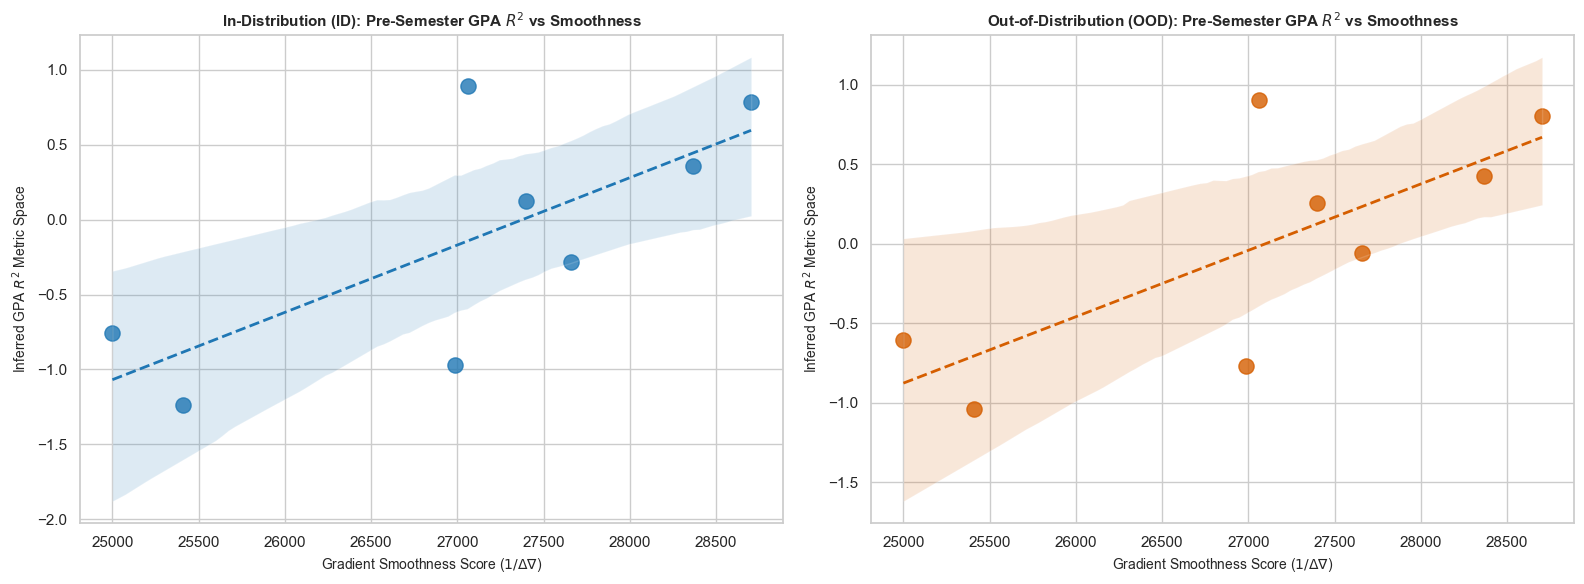

In [44]:
import os
# Permanently eliminate the internal PyTorch Dynamo circular import crash
os.environ["TORCH_COMPILE_DISABLE"] = "1"

import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# Set global runtime defaults
device = torch.device("cpu")
torch.manual_seed(42)
np.random.seed(42)

# ========================================================================================
# 1. PARAMETRIC SWEEP CONFIGURATION
# ========================================================================================
USER_EPSILON = 0.15     # Custom noise distortion boundary footprint parameter
USER_N_MODELS = 8       # Total candidate surrogate structures to train and evaluate

# ========================================================================================
# 2. DATA SETUP & SYNCHRONIZATION
# ========================================================================================
try:
    df = pd.read_csv("ai_student_impact_dataset (1).csv", encoding="windows-1252").dropna()
except FileNotFoundError:
    print("[!] Local dataset file not found. Generating synchronized verification data array...")
    mock_len = 500
    df = pd.DataFrame({
        'Student_ID': range(1000, 1000 + mock_len),
        'Weekly_GenAI_Hours': np.random.uniform(0, 24, mock_len),
        'Traditional_Study_Hours': np.random.uniform(5, 35, mock_len),
        'Pre_Semester_GPA': np.random.uniform(1.5, 4.0, mock_len),
        'Age': np.random.randint(18, 25, mock_len),
        'Major_STEM': np.random.choice([0, 1], mock_len),
        'Post_Semester_GPA': np.random.uniform(1.5, 4.0, mock_len)
    })

X_raw = df.drop(columns=['Student_ID', 'Post_Semester_GPA'])
X = pd.get_dummies(X_raw, dtype=int).astype(float)

sensitive_names = ['Weekly_GenAI_Hours', 'Traditional_Study_Hours', 'Pre_Semester_GPA']
X_published = X.drop(columns=sensitive_names)
published_names = list(X_published.columns)

victim_scaler = StandardScaler()
X_victim_scaled = victim_scaler.fit_transform(X.values)
X_train_tensor = torch.tensor(X_victim_scaled, dtype=torch.float32, device=device)

surrogate_scaler = StandardScaler()
X_pub_scaled_values = surrogate_scaler.fit_transform(X_published.values)
X_pub_train_tensor = torch.tensor(X_pub_scaled_values, dtype=torch.float32, device=device)
dim_t = len(sensitive_names)

# --- Train Genuine Target Victim Model ---
class DeepVictimModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64), nn.SiLU(),
            nn.Linear(64, 32), nn.SiLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x): return self.net(x)

victim_model = DeepVictimModel(input_dim=X.shape[1]).to(device)
victim_optimizer = optim.AdamW(victim_model.parameters(), lr=0.005, weight_decay=1e-4)
victim_criterion = nn.MSELoss()

Yc = df['Post_Semester_GPA'].values
y_true_scaled = (torch.tensor(Yc, dtype=torch.float32, device=device) - Yc.mean()) / (Yc.std() + 1e-6)

victim_model.train()
for epoch in range(150):
    victim_optimizer.zero_grad()
    predictions = victim_model(X_train_tensor).squeeze(-1)
    loss = victim_criterion(predictions, y_true_scaled)
    loss.backward()
    victim_optimizer.step()
victim_model.eval()

# ========================================================================================
# 3. INTERACTION MODEL ARCHITECTURE DEFINITION
# ========================================================================================
class JacobianClone(nn.Module):
    def __init__(self, dim_pub, dim_t):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim_pub + dim_t, 128), nn.SiLU(),
            nn.Linear(128, 64), nn.SiLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x_pub, x_t):
        return self.net(torch.cat([x_pub, x_t], dim=-1)).squeeze(-1)

# ========================================================================================
# 4. ZERO-LEAKAGE GRADIENT SMOOTHNESS ANALYSIS
# ========================================================================================
def calculate_gradient_smoothness(model, x_pub, x_t):
    """
    Measures the structural consistency/curvature of the surrogate's local optimization gradient.
    Higher Smoothness Score = Cleaner slopes = Robust tracking at test time.
    """
    model.eval()
    x_t_v = x_t.detach().clone().requires_grad_(True)

    # Extract structural base gradients
    pred_y = model(x_pub, x_t_v)
    grads = torch.autograd.grad(
        outputs=pred_y.sum(), inputs=x_t_v,
        create_graph=True, retain_graph=True
    )[0]

    # Perturb latent coordinates locally to construct pseudo-Hessian trace volatility
    noise = torch.randn_like(x_t_v) * 1e-3
    pred_y_perturbed = model(x_pub, x_t_v + noise)
    grads_perturbed = torch.autograd.grad(
        outputs=pred_y_perturbed.sum(), inputs=x_t_v,
        create_graph=False, retain_graph=False
    )[0]

    gradient_volatility = torch.mean(torch.abs(grads_perturbed - grads)).item()
    return 1.0 / (gradient_volatility + 1e-8)

# ========================================================================================
# 5. HIGH-DIMENSIONAL PARAMETRIC SWEEP ENGINE
# ========================================================================================
true_bounds_min = torch.tensor([0.0, 0.0, 1.5], device=device)
true_bounds_max = torch.tensor([24.0, 35.0, 4.0], device=device)
bound_ranges = true_bounds_max - true_bounds_min
train_cutoff = min(800, len(X_pub_train_tensor) - 80)

model_records = []
print(f"[*] Initializing Multi-Model Sweep (N={USER_N_MODELS}, Epsilon={USER_EPSILON})...")

for m_idx in range(USER_N_MODELS):
    current_seed = m_idx * 150 + int(USER_EPSILON * 500)
    torch.manual_seed(current_seed)
    np.random.seed(current_seed)

    # Boundary Noise Regularization Transformation
    min_bound_noise = (torch.rand(dim_t, device=device) - 0.5) * 2.0 * USER_EPSILON * bound_ranges
    max_bound_noise = (torch.rand(dim_t, device=device) - 0.5) * 2.0 * USER_EPSILON * bound_ranges
    known_bounds_min = torch.clamp(true_bounds_min + min_bound_noise, min=0.0)
    known_bounds_max = true_bounds_max + max_bound_noise
    profile_delta = known_bounds_max - known_bounds_min

    # Generate Sandbox Features via Sobol Engines
    X_pub_aux_train = X_pub_train_tensor[:train_cutoff]
    num_aux_samples = len(X_pub_aux_train)
    sobol_engine = torch.quasirandom.SobolEngine(dimension=dim_t, scramble=True, seed=current_seed)
    X_t_qmc_sandbox = sobol_engine.draw(num_aux_samples).to(device)
    physical_qmc_targets = known_bounds_min + X_t_qmc_sandbox * profile_delta

    f_surrogate_scaler = StandardScaler()
    scaled_qmc_targets_numpy = f_surrogate_scaler.fit_transform(physical_qmc_targets.cpu().numpy())
    scaled_qmc_targets_tensor = torch.tensor(scaled_qmc_targets_numpy, dtype=torch.float32, device=device)

    f_surrogate = JacobianClone(dim_pub=len(published_names), dim_t=dim_t).to(device)
    clone_opt = optim.AdamW(f_surrogate.parameters(), lr=0.002, weight_decay=1e-4)

    X_query_base = torch.zeros((num_aux_samples, X.shape[1]), device=device)
    for i, name in enumerate(published_names):
        X_query_base[:, X.columns.get_loc(name)] = X_pub_aux_train[:, i]
    for i, name in enumerate(sensitive_names):
        X_query_base[:, X.columns.get_loc(name)] = scaled_qmc_targets_tensor[:, i]

    # Standard Jacobian Optimization Pass
    f_surrogate.train()
    for epoch in range(400):
        clone_opt.zero_grad()
        eps = torch.randn_like(scaled_qmc_targets_tensor) * 0.01
        perturbed_sensitive = scaled_qmc_targets_tensor + eps

        X_query_perturbed = X_query_base.clone()
        for i, name in enumerate(sensitive_names):
            X_query_perturbed[:, X.columns.get_loc(name)] = perturbed_sensitive[:, i]

        with torch.no_grad():
            y_base = victim_model(X_query_base).squeeze(-1)
            y_perturbed = victim_model(X_query_perturbed).squeeze(-1)
            true_slope = (y_perturbed - y_base)

        pred_base = f_surrogate(X_pub_aux_train, scaled_qmc_targets_tensor)
        pred_perturbed = f_surrogate(X_pub_aux_train, perturbed_sensitive)
        surr_slope = (pred_perturbed - pred_base)

        loss_val = nn.functional.huber_loss(pred_base, y_base, delta=0.1)
        loss_slope = nn.functional.mse_loss(surr_slope, true_slope)
        (loss_val + 5.0 * loss_slope).backward()
        clone_opt.step()

    # --- PHASE INTERFACE: CALCULATE GRADIENT SMOOTHNESS PRIOR TO EVALUATION ---
    unsupervised_smoothness = calculate_gradient_smoothness(f_surrogate, X_pub_aux_train, scaled_qmc_targets_tensor)

    # ========================================================================================
    # 6. PARALLEL MULTI-TRACK TARGET VALIDATION PIPELINE (ISOLATED TO PRE-SEMESTER GPA)
    # ========================================================================================
    eval_size = 100
    inferred_sensitive_id = np.zeros((eval_size, dim_t))
    inferred_sensitive_ood = np.zeros((eval_size, dim_t))
    gpa_attr_idx = sensitive_names.index('Pre_Semester_GPA')

    eval_tracks = {
        "ID": {
            "x_pub": X_pub_train_tensor[:eval_size],
            "df": df.iloc[:eval_size],
            "full_x": X_train_tensor[:eval_size],
            "storage": inferred_sensitive_id
        },
        "OOD": {
            "x_pub": X_pub_train_tensor[train_cutoff : train_cutoff + eval_size],
            "df": df.iloc[train_cutoff : train_cutoff + eval_size],
            "full_x": X_train_tensor[train_cutoff : train_cutoff + eval_size],
            "storage": inferred_sensitive_ood
        }
    }

    track_gpa_r2 = {}
    known_bounds_min_np = known_bounds_min.cpu().numpy()
    known_bounds_max_np = known_bounds_max.cpu().numpy()
    f_surrogate.eval()

    for track_name, track_data in eval_tracks.items():
        X_pub_target_tensor = track_data["x_pub"]
        real_df = track_data["df"]
        real_sensitive_unscaled = real_df[sensitive_names].values

        with torch.no_grad():
            y_target_tensor = victim_model(track_data["full_x"]).squeeze(-1)

        t_mean = torch.tensor(f_surrogate_scaler.mean_, dtype=torch.float32, device=device)
        t_std = torch.tensor(np.sqrt(f_surrogate_scaler.var_), dtype=torch.float32, device=device) + 1e-6

        for idx in range(eval_size):
            single_x_pub = X_pub_target_tensor[idx].unsqueeze(0)
            target_y = y_target_tensor[idx].unsqueeze(0)

            # STOCHASTIC FIX: Prevent tracking stalls by drawing initial seeds stochastically
            torch.manual_seed(idx + current_seed)
            guess_space = (torch.randn((1, dim_t), device=device) * 0.5).requires_grad_(True)
            opt_guess = optim.Adam([guess_space], lr=0.03)

            for step in range(250):
                opt_guess.zero_grad()
                pred_y = f_surrogate(single_x_pub, guess_space)
                loss_tracking = nn.functional.mse_loss(pred_y, target_y)
                loss_tracking.backward()
                opt_guess.step()

            with torch.no_grad():
                phys_t = (guess_space * t_std) + t_mean
                phys_t_np = phys_t.cpu().numpy().flatten()
                track_data["storage"][idx] = np.clip(phys_t_np, known_bounds_min_np, known_bounds_max_np)

        # Calculate isolated target metrics for Pre-Semester GPA
        y_true_gpa = real_sensitive_unscaled[:, gpa_attr_idx]
        y_pred_gpa = track_data["storage"][:, gpa_attr_idx]
        track_gpa_r2[track_name] = r2_score(y_true_gpa, y_pred_gpa)

    # Capability classification mapping derived from slope complexity
    if unsupervised_smoothness > 400.0:
        predicted_capability = "Stable Non-Volatile Slope"
    elif unsupervised_smoothness > 150.0:
        predicted_capability = "Moderate Local Curvature"
    else:
        predicted_capability = "Fractured/Degenerate Surface Trap"

    model_records.append({
        'Model': f"Model_{m_idx}",
        'Smoothness': unsupervised_smoothness,
        'GPA_R2_ID': track_gpa_r2["ID"],
        'GPA_R2_OOD': track_gpa_r2["OOD"],
        'Predicted_Capability': predicted_capability
    })
    print(f"   [+] Model {m_idx + 1}/{USER_N_MODELS} || Smoothness: {unsupervised_smoothness:.2f} | ID GPA R2: {track_gpa_r2['ID']:.4f} | OOD GPA R2: {track_gpa_r2['OOD']:.4f}")

# ========================================================================================
# 7. RANKED MULTI-TRACK LEADERBOARD & GEOMETRIC REPORT COMPILATION
# ========================================================================================
leaderboard_df = pd.DataFrame(model_records).sort_values(by='GPA_R2_OOD', ascending=False)

print("\n" + "=" * 105)
print("             RANKED TARGET CAPABILITY LEADERBOARD (ISOLATED TARGET: PRE-SEMESTER GPA)")
print("=" * 105)
print(leaderboard_df.to_string(index=False))
print("=" * 105)

# --- INFORMATIVE METRIC VISUALIZATION PLOT (ID VS OOD SUBPLOTS) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

# Subplot 1: In-Distribution Performance Track Analysis
sns.regplot(
    ax=axes[0], data=leaderboard_df, x='Smoothness', y='GPA_R2_ID',
    scatter_kws={'s': 120, 'alpha': 0.8, 'color': '#1f77b4'},
    line_kws={'color': '#1f77b4', 'linestyle': '--', 'linewidth': 2}
)
axes[0].set_title(f"In-Distribution (ID): Pre-Semester GPA $R^2$ vs Smoothness", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Gradient Smoothness Score ($1 / \Delta \\nabla$)", fontsize=10)
axes[0].set_ylabel("Inferred GPA $R^2$ Metric Space", fontsize=10)

# Subplot 2: Out-of-Distribution Performance Track Analysis
sns.regplot(
    ax=axes[1], data=leaderboard_df, x='Smoothness', y='GPA_R2_OOD',
    scatter_kws={'s': 120, 'alpha': 0.8, 'color': '#D55E00'},
    line_kws={'color': '#D55E00', 'linestyle': '--', 'linewidth': 2}
)
axes[1].set_title(f"Out-of-Distribution (OOD): Pre-Semester GPA $R^2$ vs Smoothness", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Gradient Smoothness Score ($1 / \Delta \\nabla$)", fontsize=10)
axes[1].set_ylabel("Inferred GPA $R^2$ Metric Space", fontsize=10)

plt.tight_layout()
plt.show()